<a href="https://colab.research.google.com/github/dheerajdogra102003-create/USD_Prediction_ML/blob/main/LinearRegressionFullPipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd


In [ ]:

df=pd.read_csv('/content/r691_daily_interbank_forex_rates_usd_vis_a_vis_inr.csv')

# df.head(20)

In [ ]:
df=df.drop(columns=["src_file","tab","period","row_no","c1"], errors='ignore')



df=df.drop(index=df.index[:9], errors='ignore')
df.reset_index(drop=True,inplace=True)



try:
    if "Interbank Open Rate" not in df.columns:
        df.columns=df.iloc[0]
        df=df.iloc[1:]
        df=df.reset_index(drop=True)
except Exception:
    pass
# df.head(20)


try:
    temp=df["Interbank Low Rate"].copy()
    df["Interbank Low Rate"]=df["Interbank High Rate"]
    df["Interbank High Rate"]=temp
except KeyError:
    pass



# Clean the dataframe by converting columns to numeric and dropping any resulting NaNs
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df.dropna(inplace=True)

# Dictionary containing regression models
from sklearn.linear_model import LinearRegression, Lasso, Ridge
regression_models = {
    'LinearRegression': LinearRegression(),
    'Lasso': Lasso(),
    'Ridge': Ridge()
}

In [ ]:
temp=df["Interbank Low Rate"]
df["Interbank Low Rate"]=df["Interbank High Rate"]
df["Interbank High Rate"]=temp

#

In [ ]:
from sklearn.model_selection import train_test_split
X=df.drop(columns=["RBI Reference Rate"])
y=df["RBI Reference Rate"]
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42
)

In [ ]:
# from sklearn.pipeline import Pipeline
# from sklearn.preprocessing import StandardScaler


# from sklearn.linear_model import (
#     LinearRegression,
#     Ridge,
#     Lasso,
#     ElasticNet,
#     SGDRegressor,
#     HuberRegressor,
#     RANSACRegressor,
#     TheilSenRegressor,
#     BayesianRidge,
#     Lars,
#     LassoLars,
#     OrthogonalMatchingPursuit,
#     PassiveAggressiveRegressor,
#     PoissonRegressor,
#     TweedieRegressor,
#     ARDRegression
# )

# from sklearn.tree import DecisionTreeRegressor
# from sklearn.ensemble import (
#     RandomForestRegressor,
#     ExtraTreesRegressor,
#     GradientBoostingRegressor,
#     HistGradientBoostingRegressor,
#     AdaBoostRegressor,
#     VotingRegressor,
#     StackingRegressor,
#     BaggingRegressor,
#     RandomTreesEmbedding
# )
# from sklearn.svm import SVR, LinearSVR
# from sklearn.neighbors import KNeighborsRegressor
# from sklearn.neural_network import MLPRegressor
# from sklearn.dummy import DummyRegressor

# models = {
#     # Linear models
#     "Linear Regression": LinearRegression(),
#     "Ridge": Ridge(),
#     "Lasso": Lasso(),
#     "ElasticNet": ElasticNet(),
#     "SGD Regressor": SGDRegressor(random_state=42),
#     "Huber Regressor": HuberRegressor(),
#     "RANSAC Regressor": RANSACRegressor(random_state=42),
#     "Theil-Sen Regressor": TheilSenRegressor(),
#     "Bayesian Ridge": BayesianRidge(),
#     "Lars": Lars(),
#     "Lasso Lars": LassoLars(),
#     "Orthogonal Matching Pursuit": OrthogonalMatchingPursuit(),
#     "Passive Aggressive": PassiveAggressiveRegressor(random_state=42),
#     "Poisson Regressor": PoissonRegressor(),
#     "Tweedie Regressor": TweedieRegressor(),
#     "ARD Regression": ARDRegression(),

#     # Tree-based models
#     "Decision Tree": DecisionTreeRegressor(random_state=42),
#     "Random Forest": RandomForestRegressor(random_state=42),
#     "Extra Trees": ExtraTreesRegressor(random_state=42),
#     "Gradient Boosting": GradientBoostingRegressor(random_state=42),
#     "Hist Gradient Boosting": HistGradientBoostingRegressor(random_state=42),
#     "AdaBoost": AdaBoostRegressor(random_state=42),
#     "Bagging": BaggingRegressor(random_state=42),

#     # Support Vector Regression
#     "SVR": SVR(),
#     "Linear SVR": LinearSVR(random_state=42),

#     # Other models
#     "KNN Regressor": KNeighborsRegressor(),
#     "MLP Regressor": MLPRegressor(max_iter=1000, random_state=42),
#     "Dummy Regressor": DummyRegressor()
# }



# results = []

# for name, regressor in models.items():
#     try:
#         model = Pipeline([
#             ("scaler", StandardScaler()),
#             ("regressor", regressor)
#         ])

#         model.fit(X_train, y_train)
#         predictions = model.predict(X_test)

#         from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
#         results.append({
#             "Model": name,
#             "MAE": mean_absolute_error(y_test, predictions),
#             "RMSE": mean_squared_error(y_test, predictions) ** 0.5,
#             "R2 Score": r2_score(y_test, predictions)
#         })

#     except Exception as e:
#         print(f"{name} failed: {e}")

# results = pd.DataFrame(results)
# display(results.sort_values("MAE"))

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,Model,MAE,RMSE,R2 Score
5,Huber Regressor,0.038173,0.060849,0.999984
7,Theil-Sen Regressor,0.038259,0.060513,0.999984
24,Linear SVR,0.041725,0.064843,0.999982
18,Extra Trees,0.044634,0.068878,0.999980
17,Random Forest,0.046420,0.073895,0.999977
25,KNN Regressor,0.047380,0.073173,0.999977
1,Ridge,0.048122,0.074112,0.999977
4,SGD Regressor,0.048195,0.071894,0.999978
22,Bagging,0.048604,0.075617,0.999976
8,Bayesian Ridge,0.055504,0.087419,0.999968


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


from sklearn.linear_model import HuberRegressor



model = Pipeline([
            ("scaler", StandardScaler()),
            ("regressor", HuberRegressor())
        ])

model.fit(X_train, y_train)
predictions = model.predict(X_test)


from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
print(f"MAE:{mean_absolute_error(y_test, predictions)}    RMSE:{mean_squared_error(y_test, predictions) ** 0.5}     R2 Score: {r2_score(y_test, predictions)} ")

MAE:0.038173413361645016    RMSE:0.06084918318847117     R2 Score: 0.9999843042802941 


Pipeline(steps=[('scaler', StandardScaler()), ('regressor', HuberRegressor())])

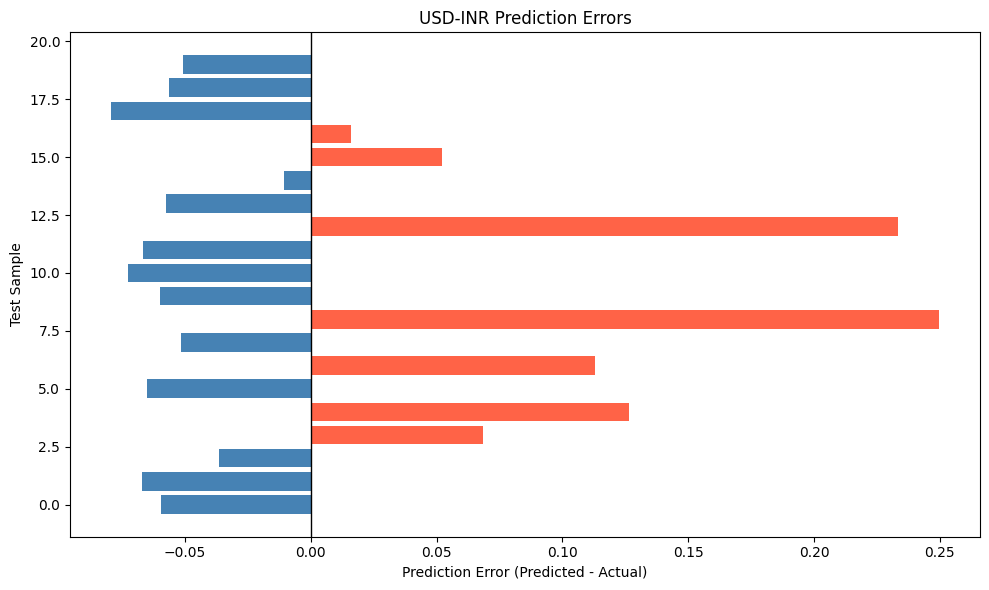

In [ ]:
errors = predicted[:20] - actual[:20]
colors = ["tomato" if e > 0 else "steelblue" for e in errors]

plt.figure(figsize=(10, 6))
plt.barh(range(len(errors)), errors, color=colors)
plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Prediction Error (Predicted - Actual)")
plt.ylabel("Test Sample")
plt.title("USD-INR Prediction Errors")
plt.tight_layout()
plt.show()

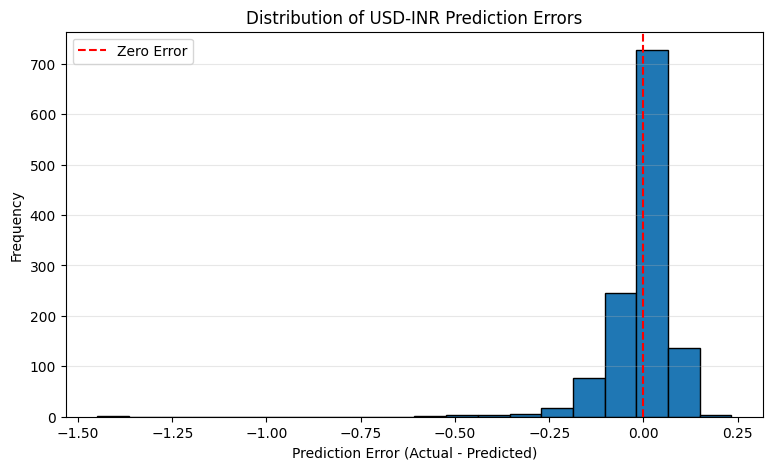

In [ ]:
errors = actual - predicted

plt.figure(figsize=(9, 5))
plt.hist(errors, bins=20, edgecolor="black")

plt.axvline(0, color="red", linestyle="--", label="Zero Error")
plt.xlabel("Prediction Error (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Distribution of USD-INR Prediction Errors")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

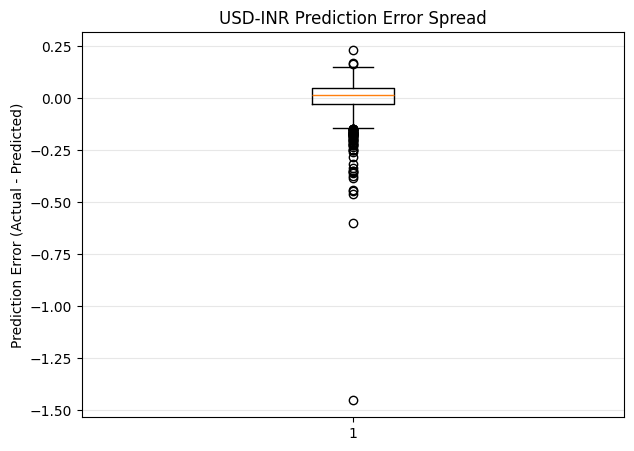

In [ ]:
plt.figure(figsize=(7, 5))
plt.boxplot(errors, vert=True)

plt.ylabel("Prediction Error (Actual - Predicted)")
plt.title("USD-INR Prediction Error Spread")
plt.grid(axis="y", alpha=0.3)
plt.show()

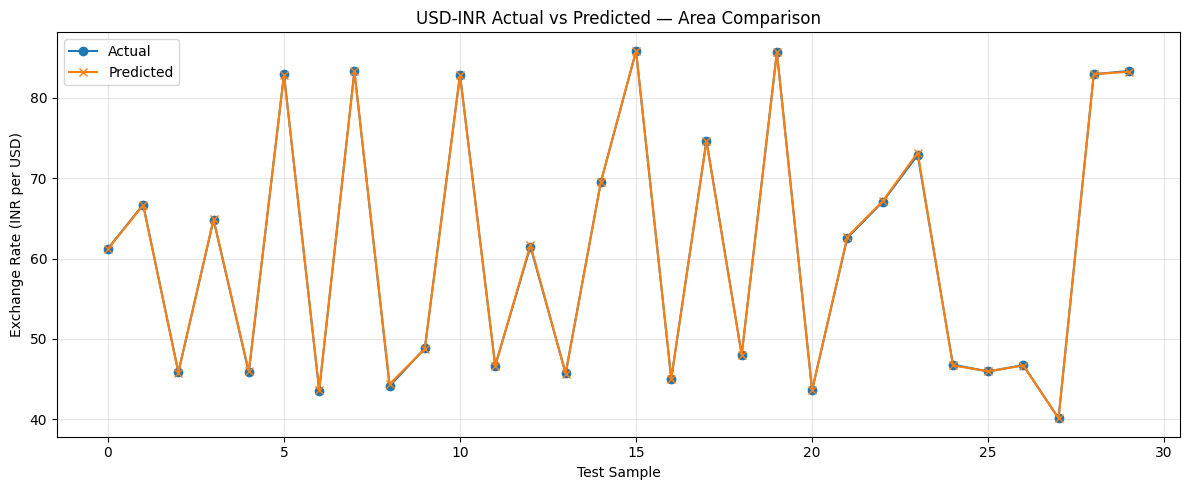

In [ ]:
n = min(30, len(actual))
x = np.arange(n)

plt.figure(figsize=(12, 5))
plt.plot(x, actual[:n], label="Actual", marker="o")
plt.plot(x, predicted[:n], label="Predicted", marker="x")

plt.fill_between(
    x, actual[:n], predicted[:n],
    alpha=0.2
)

plt.xlabel("Test Sample")
plt.ylabel("Exchange Rate (INR per USD)")
plt.title("USD-INR Actual vs Predicted — Area Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

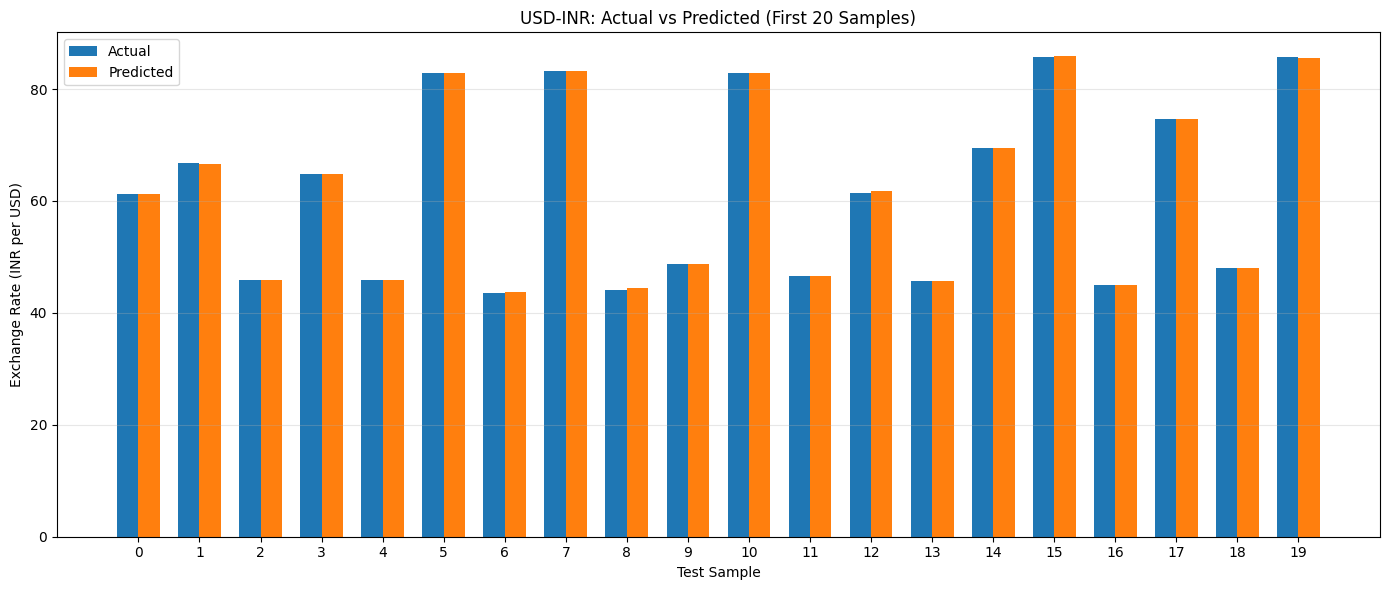

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

actual = np.asarray(y_test).flatten()
predicted = np.asarray(predict).flatten()

n = min(20, len(actual))  # Display first 20 test samples
x = np.arange(n)
width = 0.35

plt.figure(figsize=(14, 6))

plt.bar(x - width/2, actual[:n], width, label="Actual")
plt.bar(x + width/2, predicted[:n], width, label="Predicted")

plt.title("USD-INR: Actual vs Predicted (First 20 Samples)")
plt.xlabel("Test Sample")
plt.ylabel("Exchange Rate (INR per USD)")
plt.xticks(x)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

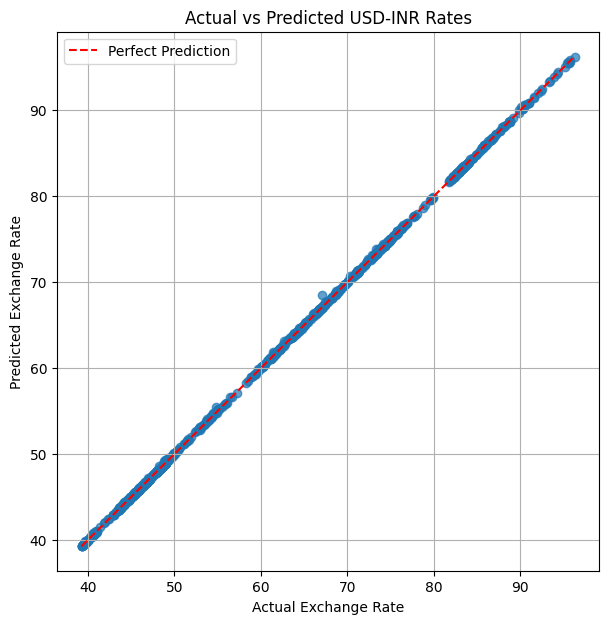

In [ ]:
plt.figure(figsize=(7, 7))

plt.scatter(y_test, predict, alpha=0.7)

# Perfect predictions should lie on this line
min_val = min(y_test.min(), predict.min())
max_val = max(y_test.max(), predict.max())

plt.plot([min_val, max_val], [min_val, max_val], "r--",
         label="Perfect Prediction")

plt.xlabel("Actual Exchange Rate")
plt.ylabel("Predicted Exchange Rate")
plt.title("Actual vs Predicted USD-INR Rates")
plt.legend()
plt.grid(True)
plt.show()

<Axes: xlabel='0', ylabel='0'>

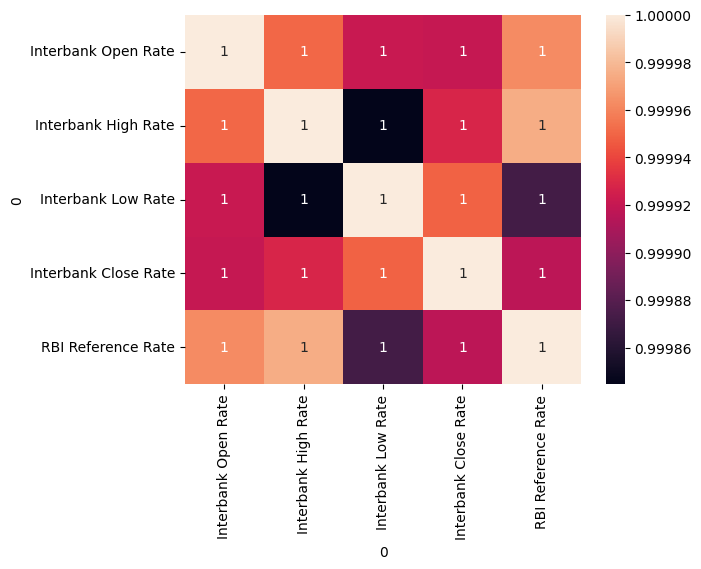

In [ ]:
import seaborn as sns
sns.heatmap(df.corr(numeric_only=True),annot=True)

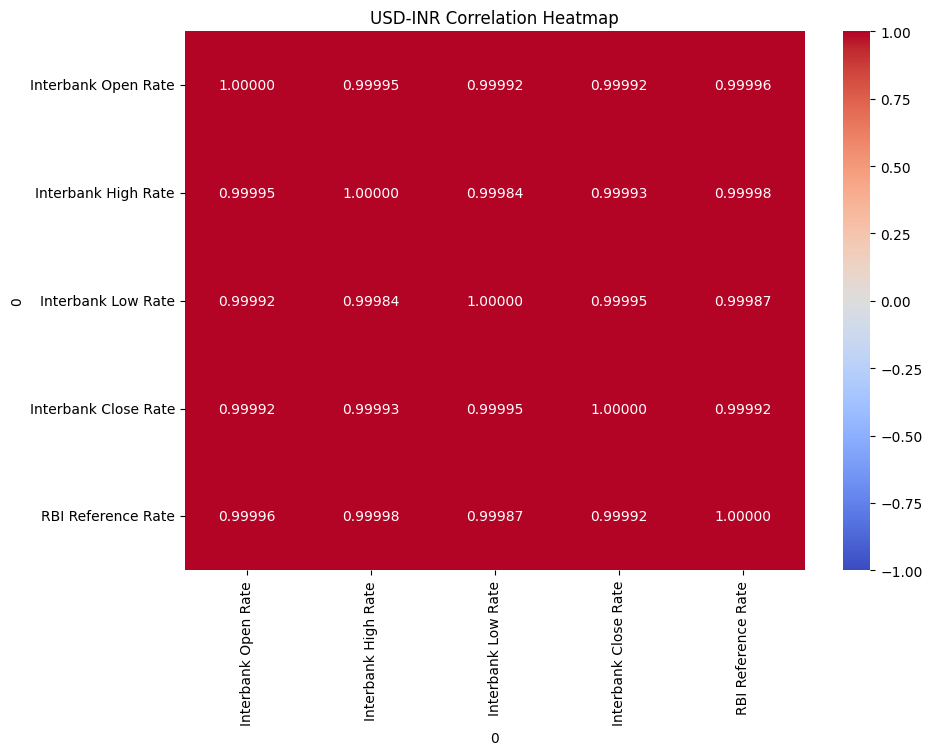

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = df.select_dtypes(include="number").corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt=".5f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.title("USD-INR Correlation Heatmap")
plt.show()

In [ ]:
# Pass the data as a pandas DataFrame with matching feature names to avoid the UserWarning
input_data = pd.DataFrame([
    [86.0, 86.89, 85.987, 86.777]
], columns=X.columns)

p = model.predict(input_data)
p

array([86.37718589])